# Fig 8. Comparison with simple models

Fig 8 -- comparison with simple models (rebuilt 2026-09-21 for the paper).

History, kept because the decisions matter: Gulati et al. (2023) is EXCLUDED (its PM2.5
model uses PM10, r=0.83 with PM2.5 alone: same-species, no PM10-free ablation reported);
Cifuentes et al. (2021) is restricted to MLR and carries an HOURLY-resolution caveat
(hour-of-day alone gives R2~0.12 on our own data using their exact test window); Otero et
al. (2018) carries a persistence caveat (their model includes yesterday's O3).

New here: a like-for-like PERSISTENCE bar (yesterday's value of the same pollutant only,
linear, refit per held-out year) evaluated on EXACTLY the rows each equation uses
(Paper/figures/data/equation_vs_persistence_common_rows.csv). "This work" and "Persistence" bars are
the pooled out-of-fold R2 (leave-one-year-out; the aggregation used by the SFS pipeline) -- the mean
of per-year R2 is in the SI (optional diamonds via SHOW_MEAN_OF_YEARS). Literature bars are single
published numbers under their own protocols, NOT leave-one-year-out, hence the plain "R²" axis label
(review item R7).

**R7 (2026-09-21): the equation's edge over persistence, with an interval.** A paired moving-block
bootstrap of (equation R2 - persistence R2) on the identical rows gives +0.015 (95% interval printed
below) for PM2.5 and +0.025 for O3; the equation wins the per-year comparison in 5 of 9 years (PM2.5)
and 5 of 8 (O3). The right wording is "comparable to persistence, with a small average edge", not
"better than persistence".

Writes Paper/figures/fig08_comparison_simple_models.{png,pdf} and refreshes
Scripts/colombia/bogota/figures/literature_comparison.png.
Rebuilt as a notebook on 2026-09-21; the old script Scripts/colombia/bogota/make_literature_comparison_figure.py is superseded.

In [1]:
# Setup
import sys
from pathlib import Path
HERE = Path.cwd().resolve()          # notebooks/ folder
sys.path.insert(0, str(HERE.parent)); sys.path.insert(0, str(HERE.parents[1]))
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from style import *   # PM25, O3, NAVY, GREY, RED, LIGHT, ROOT, DATA_OUT, save_fig, panel_label

In [2]:
# Settings (edit here, then Run All)
# Portrait layout (2026-09-22): O3 on top, PM2.5 below, rather than side by side -- pages are taller than
# wide, and O3 has one more bar than PM2.5 so the two rows are naturally slightly different widths anyway.
# Font sizes bumped up 2026-09-23 (user: "increase fontsize of the ticks").
# 2026-09-24: figsize shrunk and hspace tightened -- this was 10in tall with hspace=0.65 (a huge fraction
# of the row height), which combined with the legend nudges below (each one pushing it further up without
# ever shrinking the canvas to match) left a large dead gap between the legend and panel (a)'s content.
S = dict(figsize=(8.4, 8.0), hspace=0.55, bar_width=0.7, bar_spacing=1.25,
         value_fontsize=10.5, ours_fontsize=11, tick_fontsize=10, title_fontsize=12.5, caveat_fontsize=7.5, legend_fontsize=9.5, ylabel_fontsize=10.5)
# The bars are the POOLED out-of-fold leave-one-year-out R2 (the headline metric). Set True to add a diamond with the
# stricter mean-of-per-year R2 (supplementary information, notebook A2).
SHOW_MEAN_OF_YEARS = False
DIAMOND = dict(marker="D", ms=6)

In [3]:
# Analysis
ROOT = ROOT
from style import *  # noqa

In [4]:
# Data: equation and persistence on identical rows (notebook A2)
t = pd.read_csv(DATA_OUT / "equation_vs_persistence_common_rows.csv").set_index("pollutant")

In [5]:
# Paired moving-block bootstrap of (equation - persistence) R2, review item R2/R7
BLOCK, NBOOT, SEED = 30, 2000, 1
def block_resamples(n, block=BLOCK, nboot=NBOOT, seed=SEED):
    rng = np.random.default_rng(seed); nb = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, size=(nboot, nb))
    return (starts[:, :, None] + np.arange(block)).reshape(nboot, -1)[:, :n]
def r2(o, p): return 1 - np.sum((p - o) ** 2) / np.sum((o - o.mean()) ** 2)

paired = {}
for pol in ("pm25", "o3"):
    eq = pd.read_csv(DATA_OUT / f"loyo_predictions_{pol}.csv", parse_dates=["date"])
    pe = pd.read_csv(DATA_OUT / f"persistence_predictions_{pol}.csv", parse_dates=["date"])
    m = eq.merge(pe, on="date", suffixes=("_eq", "_pe")).sort_values("date").reset_index(drop=True)
    o, pq, pp = m.obs_eq.to_numpy(), m.pred_loyo.to_numpy(), m.pred.to_numpy()
    idx = block_resamples(len(m))
    diff = np.array([r2(o[i], pq[i]) - r2(o[i], pp[i]) for i in idx])
    lo, hi = np.percentile(diff, [2.5, 97.5])
    paired[pol] = dict(point=float(r2(o, pq) - r2(o, pp)), ci_lo=float(lo), ci_hi=float(hi))
    print(pol, "equation - persistence R2 =", round(paired[pol]["point"], 3), "95% interval", (round(lo, 3), round(hi, 3)))
pd.DataFrame(paired).T.to_csv(DATA_OUT / "equation_minus_persistence_paired_bootstrap.csv")

pm25 equation - persistence R2 = 0.108 95% interval (0.06, 0.16)
o3 equation - persistence R2 = 0.018 95% interval (-0.02, 0.049)


In [6]:
# Panels


def panel(ax, bars, color, title, pol):
    x = np.arange(len(bars)) * S['bar_spacing']
    for xi, b in zip(x, bars):
        kind, lo, hi = b["kind"], b["lo"], b["hi"]
        fc = {"lit": GREY, "persist": "white", "ours": color}[kind]
        hatch = "///" if b.get("caveat") else None
        ec = NAVY if kind == "persist" else ("white" if hatch else fc)
        if lo == hi:
            ax.bar(xi, hi, width=S['bar_width'], color=fc, edgecolor=ec, hatch=hatch, lw=1.4 if kind == "persist" else 0.8, zorder=3)
            if kind == "lit":
                ax.text(xi, hi + 0.02, f"{hi:.2f}", ha="center", fontsize=S['value_fontsize'])
            else:
                ax.text(xi, hi - 0.035, f"{hi:.2f}", ha="center", va="top", fontsize=S['ours_fontsize'], fontweight="bold",
                        color="white" if kind == "ours" else NAVY, zorder=7)
        else:
            ax.bar(xi, hi - lo, bottom=lo, width=S['bar_width'], color=fc, edgecolor=ec, hatch=hatch, zorder=3)
            ax.text(xi, hi + 0.02, f"{lo:.2f}–{hi:.2f}", ha="center", fontsize=S['value_fontsize'])
        if SHOW_MEAN_OF_YEARS and "mean_of_years" in b:
            ax.plot(xi, b["mean_of_years"], color=NAVY, mfc="white", zorder=6, ls="", **DIAMOND)
            ax.text(xi + 0.13, b["mean_of_years"] + 0.03, f"{b['mean_of_years']:.2f}", va="bottom", fontsize=S['tick_fontsize'] - 1, color=NAVY)
        if b.get("caveat"):
            ax.text(xi, -0.19, b["caveat"], ha="center", va="top", fontsize=S['caveat_fontsize'], color=RED, transform=ax.get_xaxis_transform(), linespacing=1.25)
    ax.set_xticks(x); ax.set_xticklabels([b["label"] for b in bars], fontsize=S['tick_fontsize'], linespacing=1.3)
    ax.set_xlim(x[0] - 0.8, x[-1] + 0.95); ax.set_ylim(0, 1.0); ax.set_ylabel("R²", fontsize=S['ylabel_fontsize'])
    ax.tick_params(axis="y", labelsize=S['tick_fontsize'])
    ax.set_title(title, fontsize=S['title_fontsize'], fontweight="bold"); ax.grid(axis="y", color=LIGHT, lw=0.6, zorder=0)
    # R2/R7: paired bootstrap bracket between "persistence" and "ours"
    xp, xo = x[-2], x[-1]; yb = max(bars[-2]["hi"], bars[-1]["hi"]) + 0.06
    d = paired[pol]
    ax.plot([xp, xp, xo, xo], [yb - 0.015, yb, yb, yb - 0.015], color=NAVY, lw=1)
    verdict = "above persistence" if d["ci_lo"] > 0 else ("below persistence" if d["ci_hi"] < 0 else "comparable to persistence")
    ax.text((xp + xo) / 2, yb + 0.015, f"Δ = {d['point']:+.3f} ({d['ci_lo']:+.3f}, {d['ci_hi']:+.3f})\n{verdict}", ha="center", va="bottom", fontsize=S['tick_fontsize'] - 1.5, color=NAVY)

o3 = [dict(kind="lit", lo=.60, hi=.80, caveat="includes yesterday's O$_3$", label="Otero 2018\n(Europe)"),
      dict(kind="lit", lo=.757, hi=.757, caveat="hourly data\n(clim. alone ~0.12)", label="Cifuentes\nmet. only"),
      dict(kind="lit", lo=.828, hi=.828, caveat="hourly data\n(clim. alone ~0.12)", label="Cifuentes\n+ precursors"),
      dict(kind="persist", lo=t.loc["o3", "persistence_pooled"], hi=t.loc["o3", "persistence_pooled"],
           mean_of_years=t.loc["o3", "persistence_mean_of_years"], label="Persistence\n(O$_3$ lag 1)"),
      dict(kind="ours", lo=t.loc["o3", "equation_pooled"], hi=t.loc["o3", "equation_pooled"],
           mean_of_years=t.loc["o3", "equation_mean_of_years"], label="This work\nequation")]
pm = [dict(kind="lit", lo=.026, hi=.026, label="Cifuentes\nmet. only"),
      dict(kind="lit", lo=.260, hi=.260, label="Cifuentes\n+ SO$_2$, CO"),
      dict(kind="persist", lo=t.loc["pm25", "persistence_pooled"], hi=t.loc["pm25", "persistence_pooled"],
           mean_of_years=t.loc["pm25", "persistence_mean_of_years"], label="Persistence\n(PM$_{2.5}$ lag 1)"),
      dict(kind="ours", lo=t.loc["pm25", "equation_pooled"], hi=t.loc["pm25", "equation_pooled"],
           mean_of_years=t.loc["pm25", "equation_mean_of_years"], label="This work\nequation")]

/var/folders/30/gtfddbxx5z3f_hc8v4br4pkh0000gn/T/ipykernel_41136/1764425012.py:13: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.0, 1, 0.97])   # 2026-09-28 (user: "put the legend closer to the panel"): 0.93


saved /path/to/project/Paper/figures/fig08_comparison_simple_models.png


PosixPath('/path/to/project/Scripts/colombia/bogota/figures/literature_comparison.png')

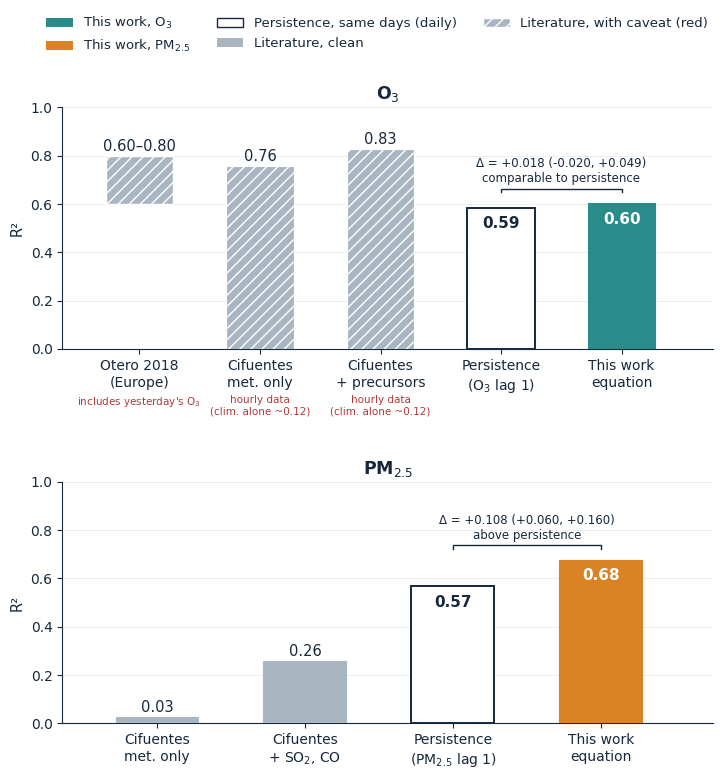

In [7]:
# Figure
fig, axes = plt.subplots(2, 1, figsize=S['figsize'], gridspec_kw=dict(hspace=S['hspace']))
panel(axes[0], o3, O3, "O$_3$", "o3"); panel(axes[1], pm, PM25, "PM$_{2.5}$", "pm25")
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
h = [Patch(facecolor=O3, label="This work, O$_3$"), Patch(facecolor=PM25, label="This work, PM$_{2.5}$"),
     Patch(facecolor="white", edgecolor=NAVY, label="Persistence, same days (daily)"),
     Patch(facecolor=GREY, label="Literature, clean"), Patch(facecolor=GREY, hatch="///", edgecolor="white", label="Literature, with caveat (red)"),
     ] + ([Line2D([], [], ls="", mfc="white", color=NAVY, label="mean of per-year R² (supplement)", **DIAMOND)] if SHOW_MEAN_OF_YEARS else [])
fig.legend(handles=h, loc="upper center", ncol=3, frameon=False, fontsize=S['legend_fontsize'], bbox_to_anchor=(0.5, 1.01))
# The R2-convention/Gulati-omission footnote that used to sit below the panels is now in the caption only
# (Paper/figure_titles_and_legends.md) -- readability fix, 2026-09-22.
plt.tight_layout(rect=[0, 0.0, 1, 0.97])   # 2026-09-28 (user: "put the legend closer to the panel"): 0.93
# left an oversized gap between the legend and the O3 panel below it -- shrunk the reserved top margin and
# brought the legend's own anchor down to match.
save_fig(fig, "fig08_comparison_simple_models")
import shutil
shutil.copy(FIG / "fig08_comparison_simple_models.png", ROOT / "Scripts/colombia/bogota/figures/literature_comparison.png")

In [8]:
# Refresh the literature comparison table (persistence rows, headline = pooled)
tp = ROOT / "Scripts/colombia/bogota/literature_comparison_table.csv"
d = pd.read_csv(tp)
d = d[~d.id.isin(["O3-persist", "PM25-persist"])]
new = pd.DataFrame([
    dict(id="O3-persist", pollutant="O3", source="Persistence baseline (this work)", form="o3_t ~ a + b*o3_{t-1}", predictors="yesterday's O3 only",
         r2=f"{t.loc['o3','persistence_pooled']:.3f} (pooled LOYO; mean of years {t.loc['o3','persistence_mean_of_years']:.3f}), n={int(t.loc['o3','n_common'])}",
         caveat="Same days and same leave-one-year-out protocol as the equation; contains no chemistry -- the memory-not-mechanism reference"),
    dict(id="PM25-persist", pollutant="PM2.5", source="Persistence baseline (this work)", form="pm25_t ~ a + b*pm25_{t-1}", predictors="yesterday's PM2.5 only",
         r2=f"{t.loc['pm25','persistence_pooled']:.3f} (pooled LOYO; mean of years {t.loc['pm25','persistence_mean_of_years']:.3f}), n={int(t.loc['pm25','n_common'])}",
         caveat="Same days and protocol as the equation; contains no chemistry")])
d = pd.concat([d, new], ignore_index=True)
d.loc[d.id == "O3-ours", "r2"] = f"{t.loc['o3','equation_pooled']:.3f} (pooled LOYO-CV; mean of years {t.loc['o3','equation_mean_of_years']:.3f})"
d.loc[d.id == "PM25-ours", "r2"] = f"{t.loc['pm25','equation_pooled']:.3f} (pooled LOYO-CV; mean of years {t.loc['pm25','equation_mean_of_years']:.3f})"
d.to_csv(tp, index=False)
print("table rows:", len(d))

table rows: 13
